# Taller MLP – Predicción de aprobación de estudiantes
Metodología CRISP-DM: datos → preparación → modelado → evaluación → despliegue.

## 1. Carga de datos y revisión del balanceo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score
import joblib

df = pd.read_csv('dataset_estudiantes_balanceado.csv')
print(df.shape)
df.head()

(600, 8)


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Calificacion_Final,Aprobado
0,56.217808,33.514805,85.495792,23.999532,5.703021,1,79.671652,1
1,96.550001,42.287227,41.475215,18.962692,4.358559,1,82.650731,1
2,81.239576,34.160839,41.327413,10.124782,6.048144,0,60.380195,0
3,71.906094,27.096203,59.416613,13.791209,5.556087,1,63.816827,0
4,40.921305,29.650870,69.806012,10.043174,7.385603,0,49.874904,0


In [2]:
# Objetivo 1: balanceo de clases (50% / 50%)
print(df['Aprobado'].value_counts(normalize=True))

Aprobado
1    0.5
0    0.5
Name: proportion, dtype: float64


## 2. Valores ausentes

In [3]:
print(df.isna().sum())

Tareas                0
Examenes              0
Asistencia            0
Estudio_Horas         0
Sueno_Horas           0
Extracurriculares     0
Calificacion_Final    0
Aprobado              0
dtype: int64


## 3. Variables de entrada (features) y objetivo
Se excluye `Calificacion_Final` porque la etiqueta `Aprobado` se construyó a partir de ella: usarla sería *fuga de información* (el modelo "haría trampa").

In [4]:
FEATURES = ['Tareas', 'Examenes', 'Asistencia', 'Estudio_Horas', 'Sueno_Horas', 'Extracurriculares']
X = df[FEATURES]
y = df['Aprobado']

# 80% entrenamiento / 20% prueba independiente, manteniendo la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(480, 6) (120, 6)


## 4. Pipeline: imputación (mediana) + estandarización (media 0, varianza 1) + MLP
- `SimpleImputer(strategy='median')`: rellena faltantes con la mediana de cada columna.
- `StandardScaler`: deja cada variable con media 0 y varianza 1.
- `MLPClassifier`: 2 capas ocultas (16 y 8 neuronas), activación ReLU, optimizador Adam y regularización L2 (alpha=0.01) para evitar sobreajuste.

In [5]:
modelo = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam',
                          alpha=0.01, max_iter=2000, random_state=42))
])
modelo.fit(X_train, y_train)

# Verificación del escalado
Xs = modelo.named_steps['scaler'].transform(modelo.named_steps['imputer'].transform(X_train))
print('Medias :', Xs.mean(axis=0).round(2))
print('Varianzas:', Xs.var(axis=0).round(2))

Medias : [ 0.  0.  0. -0. -0.  0.]
Varianzas: [1. 1. 1. 1. 1. 1.]


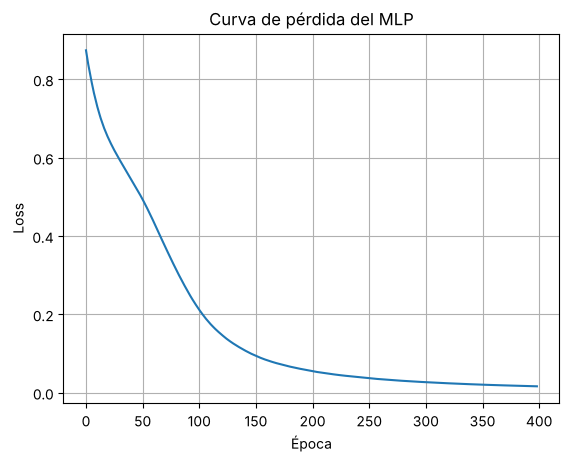

In [6]:
plt.plot(modelo.named_steps['mlp'].loss_curve_)
plt.title('Curva de pérdida del MLP'); plt.xlabel('Época'); plt.ylabel('Loss'); plt.grid(True); plt.show()

## 5. Evaluación en el set de prueba

In [7]:
y_pred = modelo.predict(X_test)
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=['Reprobado', 'Aprobado']))

Accuracy: 0.9833
              precision    recall  f1-score   support

   Reprobado       0.98      0.98      0.98        60
    Aprobado       0.98      0.98      0.98        60

    accuracy                           0.98       120
   macro avg       0.98      0.98      0.98       120
weighted avg       0.98      0.98      0.98       120



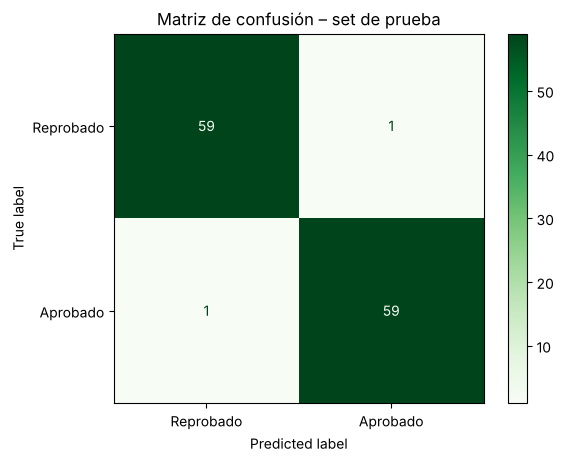

In [8]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Reprobado', 'Aprobado']).plot(cmap='Greens')
plt.title('Matriz de confusión – set de prueba'); plt.show()

In [9]:
# Contraste de aciertos: real vs predicho
contraste = X_test.copy()
contraste['Real'] = y_test.values
contraste['Predicho'] = y_pred
contraste['Acierto'] = contraste['Real'] == contraste['Predicho']
print('Aciertos:', contraste['Acierto'].sum(), 'de', len(contraste))
contraste.head(10)

Aciertos: 118 de 120


,Tareas,Examenes,Asistencia,Estudio_Horas,Sueno_Horas,Extracurriculares,Real,Predicho,Acierto
301,67.194824,22.122576,68.750913,14.259664,8.880069,1,0,0,True
90,38.371597,45.894339,63.815397,4.281096,5.428918,0,0,0,True
270,86.655281,49.864745,74.020976,19.405285,7.224163,0,1,1,True
389,86.478432,85.528185,83.055866,17.294653,8.974096,1,1,1,True
117,43.059904,97.202153,83.895371,15.640020,6.384217,0,1,1,True
507,87.577607,80.659078,52.962291,16.192530,5.130627,0,1,1,True
259,36.802355,25.256691,79.533128,14.544933,7.286767,1,0,0,True
53,92.637915,79.635158,47.511148,21.469830,5.736385,0,1,1,True
366,97.283339,77.523672,80.052994,16.585269,6.648299,0,1,1,True
115,91.002241,94.362332,78.614662,18.607632,8.631913,1,1,1,True


## 6. Guardar el modelo (lo usa la app de Streamlit)

In [10]:
joblib.dump(modelo, 'modelo_mlp.pkl')
print('Modelo guardado')

Modelo guardado


## 7. Predicción de un estudiante nuevo

In [11]:
nuevo = pd.DataFrame([[80, 75, 90, 10, 7, 1]], columns=FEATURES)
print('Predicción:', 'Aprobado' if modelo.predict(nuevo)[0] == 1 else 'Reprobado')
print('Probabilidad de aprobar:', round(modelo.predict_proba(nuevo)[0][1], 3))

Predicción: Aprobado
Probabilidad de aprobar: 1.0


## 8. Conclusiones
1. **Balanceo:** el dataset tiene 300 aprobados y 300 reprobados (50/50). Por eso el *Accuracy* es una métrica confiable aquí; con clases desbalanceadas podría ser engañoso y habría que mirar más el Recall y el F1 de la clase minoritaria.
2. **Preparación:** no había valores ausentes, pero el pipeline incluye imputación por mediana para que el modelo soporte datos incompletos en producción. El escalado dejó todas las variables con media 0 y varianza 1, lo cual es necesario porque el MLP es sensible a la escala (las horas de sueño y las notas 0–100 no son comparables sin escalar).
3. **Fuga de información:** se excluyó `Calificacion_Final` porque la etiqueta se construyó a partir de ella; incluirla daría un 100% artificial.
4. **Rendimiento:** en el set de prueba independiente (120 estudiantes) el MLP acierta 118 (Accuracy ≈ 98%). Precisión, Recall y F1 son ≈ 0.98 en ambas clases, es decir, el modelo no favorece a ninguna.
5. **Matriz de confusión:** solo 2 errores, uno de cada tipo. En este contexto el error más costoso es el **falso negativo de riesgo**: predecir *Aprobado* a quien va a reprobar, porque ese estudiante se queda sin apoyo. Si la institución quiere detectar a todos los estudiantes en riesgo, conviene priorizar el **Recall de la clase Reprobado**.
6. **Proceso:** una primera versión con *early stopping* obtuvo solo 72%, porque con pocos datos apartar el 10% para validación interna dejó al modelo sin entrenar lo suficiente. Ajustar los hiperparámetros fue clave.
7. **Observación:** como la nota final es una combinación lineal de las variables, una regresión logística obtiene un resultado similar. El MLP funciona bien, pero en problemas casi lineales un modelo más simple puede ser igual de bueno y más fácil de explicar.